<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp04_ANN_Backpropagation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 4: Artificial Neural Network with Backpropagation
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Build an Artificial Neural Network by implementing the Backpropagation algorithm and test the same using appropriate data sets.

## Background
A feed-forward network computes `a_l = sigmoid(a_(l-1) W_l + b_l)` layer by layer (**forward pass**). The error is propagated backwards using the chain rule (**backpropagation**): for sigmoid output with cross-entropy loss `delta_L = a_L - y`, and for hidden layers `delta_l = (delta_(l+1) W_(l+1)^T) * a_l * (1 - a_l)`. Weights are updated by gradient descent: `W = W - lr * dW`.



## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
We use the **Breast Cancer Wisconsin (Diagnostic)** dataset bundled with scikit-learn: 569 patients, 30 numeric features computed from cell-nucleus images, label = malignant / benign. We save it to CSV.

In [2]:
from sklearn.datasets import load_breast_cancer

raw = load_breast_cancer(as_frame=True)
raw.frame.to_csv("breast_cancer.csv", index=False)
print("Saved breast_cancer.csv")

Saved breast_cancer.csv


## Step 2: Data Loading

In [3]:
df = pd.read_csv("breast_cancer.csv")
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## Step 3: Data Preprocessing
Neural networks are sensitive to feature scale, so we standardise the inputs. We split into train / validation / test sets (stratified).

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns="target").values
y = df["target"].values.reshape(-1, 1)          # 0 = malignant, 1 = benign

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

scaler = StandardScaler().fit(X_train)           # fit on training data only (no leakage)
X_train, X_val, X_test = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)
print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

Train: (364, 30) Validation: (91, 30) Test: (114, 30)


## Step 4: Exploratory Data Analysis (EDA)

diagnosis
benign       357
malignant    212
Name: count, dtype: int64
Missing values: 0


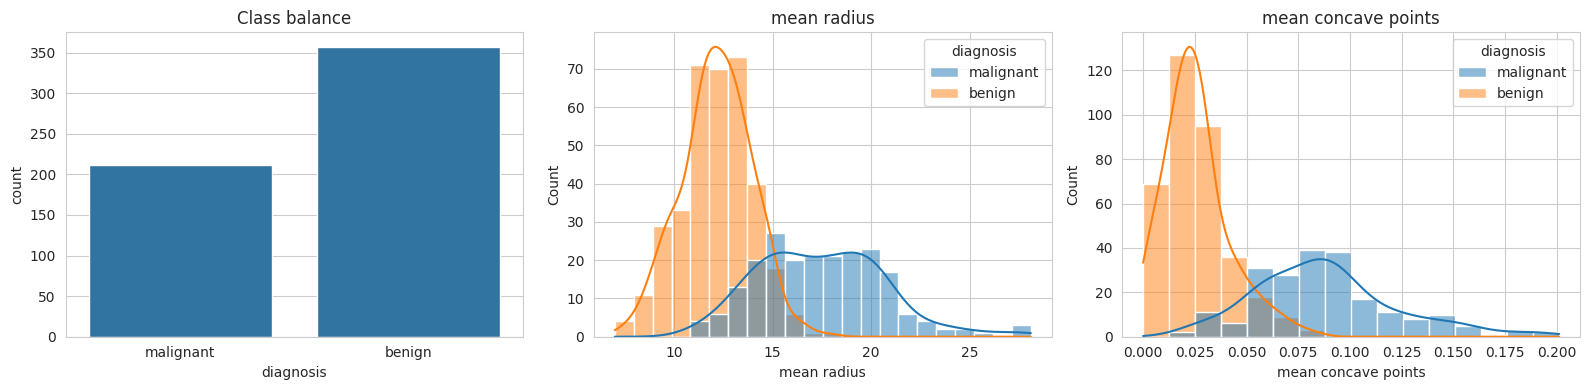

In [5]:
df_eda = df.copy()
df_eda["diagnosis"] = df_eda["target"].map({0: "malignant", 1: "benign"})
print(df_eda["diagnosis"].value_counts())
print("Missing values:", df.isnull().sum().sum())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df_eda, x="diagnosis", ax=axes[0])
axes[0].set_title("Class balance")
for ax, col in zip(axes[1:], ["mean radius", "mean concave points"]):
    sns.histplot(data=df_eda, x=col, hue="diagnosis", kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

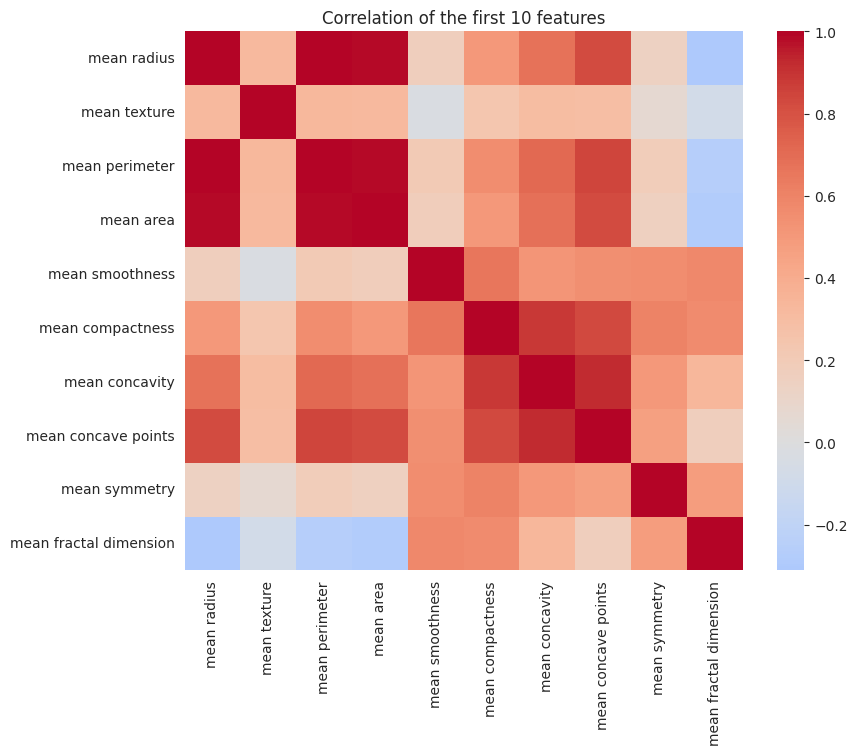

In [6]:
plt.figure(figsize=(9, 7))
corr = df.iloc[:, :10].corr()
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation of the first 10 features"); plt.show()

## Step 5: Model Training (Backpropagation from scratch)
A fully-connected network with sigmoid activations, written with plain NumPy. First, a **gradient check** proves that our backpropagation gradients match numerical gradients.

In [7]:
class NeuralNetwork:
    def __init__(self, layer_sizes, lr=0.1, seed=42):
        rng = np.random.RandomState(seed)
        self.lr = lr
        self.W = [rng.randn(i, o) * np.sqrt(1.0 / i) for i, o in zip(layer_sizes[:-1], layer_sizes[1:])]
        self.b = [np.zeros((1, o)) for o in layer_sizes[1:]]

    @staticmethod
    def sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def forward(self, X):
        activations = [X]
        for W, b in zip(self.W, self.b):
            activations.append(self.sigmoid(activations[-1] @ W + b))
        return activations

    def loss(self, X, y):
        p = np.clip(self.forward(X)[-1], 1e-12, 1 - 1e-12)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def backward(self, activations, y):
        m = y.shape[0]
        grads_W, grads_b = [], []
        delta = activations[-1] - y                               # output layer error
        for l in reversed(range(len(self.W))):
            grads_W.insert(0, activations[l].T @ delta / m)
            grads_b.insert(0, delta.sum(axis=0, keepdims=True) / m)
            if l > 0:
                delta = (delta @ self.W[l].T) * activations[l] * (1 - activations[l])
        return grads_W, grads_b

    def fit(self, X, y, X_val=None, y_val=None, epochs=1000, verbose=200):
        history = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
        for epoch in range(1, epochs + 1):
            acts = self.forward(X)
            gW, gb = self.backward(acts, y)
            for l in range(len(self.W)):
                self.W[l] -= self.lr * gW[l]
                self.b[l] -= self.lr * gb[l]
            history["loss"].append(self.loss(X, y))
            history["acc"].append(self.score(X, y))
            if X_val is not None:
                history["val_loss"].append(self.loss(X_val, y_val))
                history["val_acc"].append(self.score(X_val, y_val))
            if verbose and epoch % verbose == 0:
                print(f"Epoch {epoch:>4} | loss {history['loss'][-1]:.4f} | acc {history['acc'][-1]:.4f}"
                      + (f" | val_loss {history['val_loss'][-1]:.4f} | val_acc {history['val_acc'][-1]:.4f}" if X_val is not None else ""))
        return history

    def predict_proba(self, X):
        return self.forward(X)[-1]

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

    def score(self, X, y):
        return float(np.mean(self.predict(X) == y))

# ---- Gradient check on a tiny network ----
rng = np.random.RandomState(0)
Xc, yc = rng.randn(5, 3), rng.randint(0, 2, (5, 1))
net = NeuralNetwork([3, 4, 1])
gW, _ = net.backward(net.forward(Xc), yc)
eps, i, j = 1e-5, 1, 2
net.W[0][i, j] += eps;  l_plus = net.loss(Xc, yc)
net.W[0][i, j] -= 2 * eps; l_minus = net.loss(Xc, yc)
net.W[0][i, j] += eps
print("Backprop gradient :", gW[0][i, j])
print("Numerical gradient:", (l_plus - l_minus) / (2 * eps))

Backprop gradient : 0.020496584294931362
Numerical gradient: 0.020496584296481046


In [8]:
nn = NeuralNetwork([X_train.shape[1], 16, 8, 1], lr=0.5)
history = nn.fit(X_train, y_train, X_val, y_val, epochs=1000, verbose=200)

Epoch  200 | loss 0.0583 | acc 0.9890 | val_loss 0.0795 | val_acc 0.9670
Epoch  400 | loss 0.0450 | acc 0.9918 | val_loss 0.0750 | val_acc 0.9670
Epoch  600 | loss 0.0400 | acc 0.9918 | val_loss 0.0755 | val_acc 0.9780
Epoch  800 | loss 0.0367 | acc 0.9918 | val_loss 0.0770 | val_acc 0.9780
Epoch 1000 | loss 0.0341 | acc 0.9918 | val_loss 0.0790 | val_acc 0.9780


## Step 6: Model Evaluation
Learning curves, test-set metrics, confusion matrix and ROC curve. We also compare with scikit-learn's `MLPClassifier` as a sanity check.

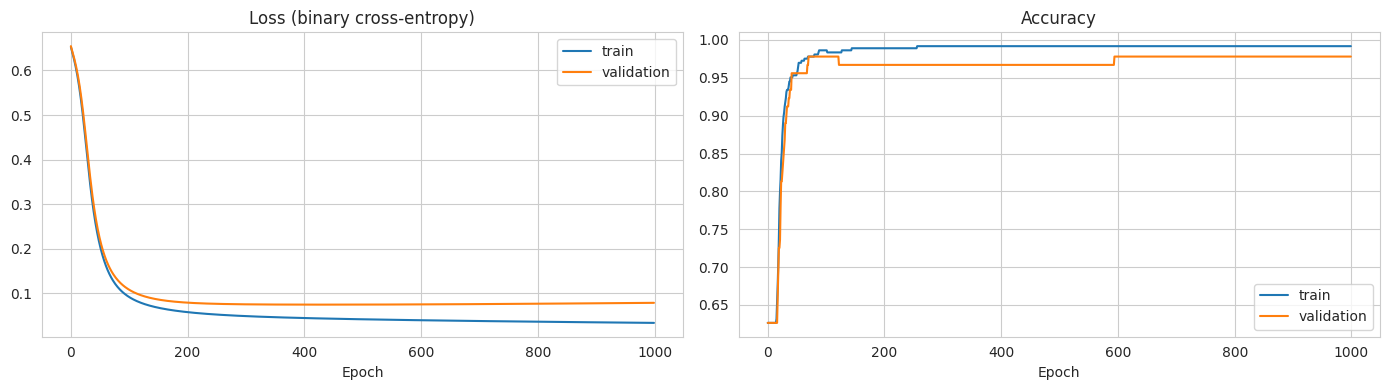

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history["loss"], label="train"); axes[0].plot(history["val_loss"], label="validation")
axes[0].set_title("Loss (binary cross-entropy)"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history["acc"], label="train"); axes[1].plot(history["val_acc"], label="validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

Test accuracy: 0.956140350877193
ROC-AUC      : 0.9957010582010581
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



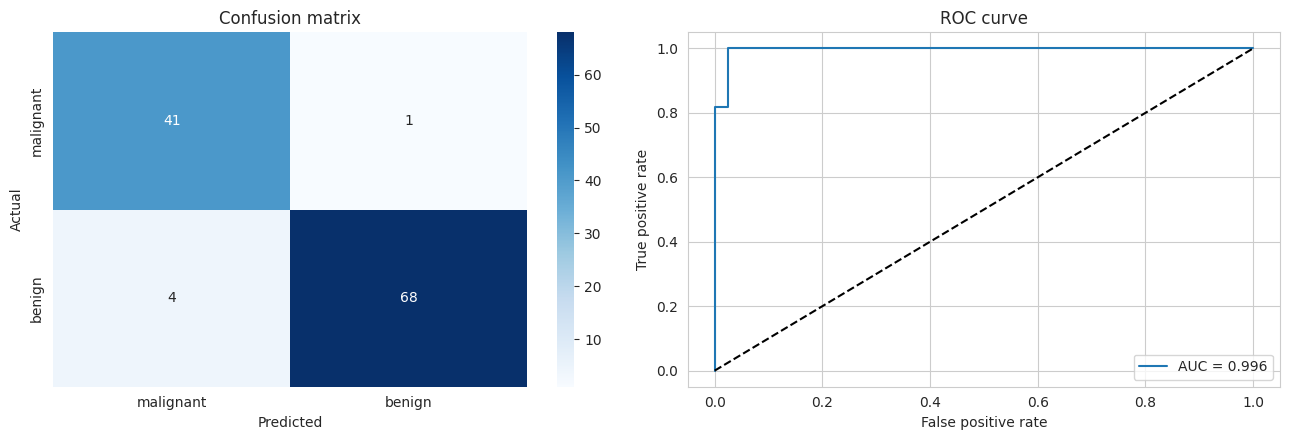

sklearn MLPClassifier test accuracy (reference): 0.9473684210526315


In [10]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, roc_auc_score
from sklearn.neural_network import MLPClassifier

y_pred = nn.predict(X_test)
y_prob = nn.predict_proba(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC      :", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion matrix")
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}"); axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curve"); axes[1].legend()
plt.tight_layout(); plt.show()

mlp = MLPClassifier(hidden_layer_sizes=(16, 8), activation="logistic", max_iter=2000, random_state=42)
mlp.fit(X_train, y_train.ravel())
print("sklearn MLPClassifier test accuracy (reference):", mlp.score(X_test, y_test.ravel()))

## Step 7: Prediction on New Data
Predict the diagnosis for a few unseen patients (taken from the test set here; for a real new patient, apply the same `scaler` first).

In [11]:
for idx in range(5):
    prob = nn.predict_proba(X_test[idx:idx + 1])[0, 0]
    label = "benign" if prob >= 0.5 else "malignant"
    actual = "benign" if y_test[idx, 0] == 1 else "malignant"
    print(f"Patient {idx}: P(benign) = {prob:.3f} -> predicted {label:<9} | actual {actual}")

Patient 0: P(benign) = 0.001 -> predicted malignant | actual malignant
Patient 1: P(benign) = 0.998 -> predicted benign    | actual benign
Patient 2: P(benign) = 0.002 -> predicted malignant | actual malignant
Patient 3: P(benign) = 0.227 -> predicted malignant | actual benign
Patient 4: P(benign) = 0.001 -> predicted malignant | actual malignant


## Conclusion
The backpropagation implementation passed the numerical gradient check and trained a 30-16-8-1 network that reaches roughly 95-97% test accuracy (ROC-AUC about 0.99), on par with scikit-learn's MLP. Learning curves show smooth convergence without heavy overfitting. Tuning the learning rate, layer sizes or adding regularisation / early stopping are natural extensions.